# Landsat 9 single-scene extraction over one PICS patch

**Purpose.** Prototype for the Landsat 9 control analysis (does the small negative EMIT drift also appear in a
well-calibrated reference sensor?). This notebook extracts **one** Landsat 9 scene over a single PICS patch,
windows it to the *same* patch polygon the EMIT pipeline uses, and reports the in-patch per-band value — the
building block for the eventual quasi-BRDF drift fit.

It reuses `emit_pics.paths` / `emit_pics.config` so the patch geometry, CRS, and site tokens are identical to
the EMIT side. Nothing here is wired into `run_pipeline.py` yet — it is an exploratory notebook.

## Products & access (why the two `SOURCE` options)

Landsat 9 = OLI-2. Collection 2 offers two levels:
- **Level-1** → DN + MTL rescaling factors → **TOA reflectance** (the analog to EMIT L1B radiance; where
  Landsat's onboard-calibration stability guarantee lives most directly). **This is what we want.**
- **Level-2** → **surface reflectance** (LaSRC; analog to EMIT L2A reflectance, but inherits the atmospheric
  correction).

Access gotcha discovered while building this: **Planetary Computer does *not* host Landsat 8/9 Level-1** (its
`landsat-c2-l1` collection is Landsat 1–5 MSS only). L9 TOA lives in the USGS `usgs-landsat` S3 bucket
(**requester-pays**, us-west-2), indexed by the LandsatLook STAC server — so it needs AWS credentials.

Hence two switchable sources:

| `SOURCE` | Product | STAC endpoint | Setup |
|---|---|---|---|
| `"usgs_toa"` *(default; what we asked for)* | **TOA reflectance** (L1) | LandsatLook | AWS creds + requester-pays |
| `"mpc_sr"` *(zero-setup fallback)* | surface reflectance (L2) | Planetary Computer | none |

Start on `mpc_sr` to prove out the patch-windowing/plotting end-to-end with no credentials, then flip to
`usgs_toa` once AWS is configured. The band-extraction and stats code is shared.

## Dependencies

Beyond the `emit-pics` env this needs `pystac-client`, `rasterio` (windowed COG reads), plus
`planetary-computer` (SR fallback) and `boto3` (MTL read from requester-pays S3 for TOA):

```bash
pip install pystac-client rasterio planetary-computer boto3
```

In [1]:
import os
import json
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from pystac_client import Client

from emit_pics import paths, config

# GDAL/AWS knobs for cloud COG reads. Harmless for the (public, signed) MPC path;
# required for the USGS requester-pays bucket. Real AWS credentials still come from
# your environment / ~/.aws (boto3 default chain).
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif,.TIF,.tiff")
os.environ.setdefault("AWS_REQUEST_PAYER", "requester")
os.environ.setdefault("AWS_REGION", "us-west-2")
os.environ.setdefault("AWS_DEFAULT_REGION", "us-west-2")

'us-west-2'

## Configuration

Same site/patch convention as the EMIT pipeline. Default target is Libya 4, patch `10_7_1` (the primary
best-covered BRDF patch), over the manuscript's EMIT window.

In [2]:
SOURCE = "usgs_toa"          # "usgs_toa" (Level-1 TOA, needs AWS) | "mpc_sr" (Level-2 SR, no setup)

SITE = "Libya 4"
PATCH = "10_7_1"
DATE_START = "2022-08-17"  # EMIT record window (manuscript)
DATE_END = "2026-06-23"
MAX_CLOUD = 5.0            # scene-level eo:cloud_cover ceiling (%), filtered client-side

# OLI-2 reflective bands. `n` is the MTL band number (for TOA rescaling); `asset` is the STAC
# asset key (common name, shared by both servers). The two flagged bands land on EMIT's
# significant-drift regions — the tests that actually matter for the control analysis.
BANDS = [
    # asset,     n, center_nm, emit_note
    ("coastal",  1,  443, ""),
    ("blue",     2,  482, ""),
    ("green",    3,  561, ""),
    ("red",      4,  655, ""),
    ("nir08",    5,  865, "<- EMIT 858 nm (significant)"),
    ("swir16",   6, 1609, ""),
    ("swir22",   7, 2201, "<- EMIT 2000-2370 nm (significant)"),
]

# Per-source STAC settings.
SOURCES = {
    "usgs_toa": dict(
        url="https://landsatlook.usgs.gov/stac-server",
        collection="landsat-c2l1",
        platform="LANDSAT_9",
        product="TOA reflectance",
    ),
    "mpc_sr": dict(
        url="https://planetarycomputer.microsoft.com/api/stac/v1",
        collection="landsat-c2-l2",
        platform="landsat-9",
        product="surface reflectance",
    ),
}
SRC = SOURCES[SOURCE]
print(f"SOURCE={SOURCE!r}  ->  {SRC['product']} via {SRC['url']}")

SOURCE='usgs_toa'  ->  TOA reflectance via https://landsatlook.usgs.gov/stac-server


## Credential check (TOA path only)

The `usgs_toa` product reads from the USGS **requester-pays** S3 bucket, which needs AWS credentials (picked up from `~/.aws/credentials` via the boto3 default chain — nothing is hard-coded here). This cell verifies access **before** the full extraction, so a misconfiguration fails here with a clear message instead of deep in the read loop. It self-skips on the free `mpc_sr` path.

In [3]:
from botocore.exceptions import BotoCoreError, ClientError
import boto3

if SOURCE != "usgs_toa":
    print("SOURCE is not 'usgs_toa' — skipping AWS credential check (not needed for the MPC SR path).")
else:
    try:
        ident = boto3.client("sts", region_name="us-west-2").get_caller_identity()
        print("credentials found   | account", ident["Account"], "| arn", ident["Arn"])
        # Representative requester-pays read from the Landsat bucket (Libya 4 = WRS 181/040).
        s3 = boto3.client("s3", region_name="us-west-2")
        r = s3.list_objects_v2(
            Bucket="usgs-landsat",
            Prefix="collection02/level-1/standard/oli-tirs/2024/181/040/",
            MaxKeys=1, RequestPayer="requester")
        keys = [o["Key"] for o in r.get("Contents", [])]
        if keys:
            print("requester-pays read OK | sample:", keys[0])
            print("TOA path is ready.")
        else:
            print("credentials OK, but no objects under the test prefix (harmless).")
    except (BotoCoreError, ClientError) as e:
        print("CREDENTIAL CHECK FAILED:", type(e).__name__, "-", e)
        print("Fix: confirm C:/Users/huckr/.aws/credentials holds your real key id + secret,")
        print("then restart the kernel (credentials are read when the client is created).")

credentials found   | account 808454010670 | arn arn:aws:iam::808454010670:user/landsat-read
requester-pays read OK | sample: collection02/level-1/standard/oli-tirs/2024/181/040/LC08_L1TP_181040_20240109_20240122_02_T1/LC08_L1TP_181040_20240109_20240122_02_T1_ANG.txt
TOA path is ready.


## Load the patch polygon

Straight from the EMIT pipeline's patch-boundary GeoPackage (in the site's UTM CRS), so we window Landsat to
the exact same footprint.

In [4]:
patches = gpd.read_file(paths.patch_bnds(SITE))
sel = patches[patches["patch_id"] == PATCH]
if sel.empty:
    raise ValueError(f"Patch {PATCH!r} not found. Available: {sorted(patches['patch_id'])[:10]} ...")

patch_geom = sel.geometry.iloc[0]
patch_crs = patches.crs                      # site UTM (e.g. EPSG:32634 for Libya 4)
patch_bounds = patch_geom.bounds             # (minx, miny, maxx, maxy) in patch_crs
patch_wgs84 = sel.to_crs(4326).geometry.iloc[0]

print(f"{config.canonical_token(SITE)}  patch {PATCH}  CRS {patch_crs.to_string()}")
print("bounds (UTM m):", tuple(round(v) for v in patch_bounds))
print("centroid (lon,lat):", (round(patch_wgs84.centroid.x, 4), round(patch_wgs84.centroid.y, 4)))

Libya_4  patch 10_7_1  CRS EPSG:32634
bounds (UTM m): (703826, 3130479, 713826, 3140479)
centroid (lon,lat): (23.1301, 28.3289)


## STAC search → pick one scene

Query the source for Landsat 9 scenes overlapping the patch in the window, then keep the least-cloudy scene
that **fully contains** the patch. Plain `intersects` also returns edge-clipping / adjacent-WRS-path scenes
that only partially cover it (the diagonal-fill artifact), so we filter on containment. Cloud filtering is
client-side, so it works identically on both STAC servers.

In [5]:
catalog = Client.open(SRC["url"])
search = catalog.search(
    collections=[SRC["collection"]],
    intersects=patch_wgs84.__geo_interface__,
    datetime=f"{DATE_START}/{DATE_END}",
)
items = list(search.items())

# Keep Landsat 9 scenes that (a) are under the cloud ceiling and (b) FULLY CONTAIN the
# patch. `intersects` also returns edge-clipping / adjacent-WRS-path scenes that cover
# it only partially (the diagonal-fill artifact); require containment to drop those.
# Then sort survivors by cloud cover and pick the lowest.
from shapely.geometry import shape

def _plat(it):
    return str(it.properties.get("platform", "")).lower().replace("_", "-")
def _cloud(it):
    return it.properties.get("eo:cloud_cover", 100.0)
def _covers(it):
    try:
        return shape(it.geometry).buffer(0).contains(patch_wgs84)
    except Exception:
        return False

cloud_ok = [it for it in items if _plat(it) == "landsat-9" and _cloud(it) <= MAX_CLOUD]
l9 = [it for it in cloud_ok if _covers(it)]
l9.sort(key=_cloud)
print(f"{len(items)} items returned; {len(cloud_ok)} L9 under {MAX_CLOUD}% cloud; "
      f"{len(l9)} of those fully cover the patch")
if not l9:
    raise RuntimeError("No fully-covering Landsat 9 scenes — relax MAX_CLOUD or the date window.")

item = l9[0]
print("chosen scene:")
print(" id        :", item.id)
print(" datetime  :", item.properties.get("datetime"))
print(" cloud %   :", _cloud(item))
print(" sun_elev  :", item.properties.get("view:sun_elevation"))
print(" WRS p/r   :", item.properties.get("landsat:wrs_path"), "/", item.properties.get("landsat:wrs_row"))
print(" asset keys:", sorted(item.assets)[:15], "...")

578 items returned; 222 L9 under 5.0% cloud; 147 of those fully cover the patch
chosen scene:
 id        : LC09_L1TP_181041_20260615_20260615_02_T1
 datetime  : 2026-06-15T08:54:53.581105Z
 cloud %   : 0
 sun_elev  : 68.90954639
 WRS p/r   : 181 / 041
 asset keys: ['ANG.txt', 'MTL.json', 'MTL.txt', 'MTL.xml', 'SAA', 'SZA', 'VAA', 'VZA', 'blue', 'cirrus', 'coastal', 'green', 'index', 'lwir11', 'lwir12'] ...


## Access helpers

- `resolve_href` — sign MPC hrefs; prefer the `s3://` alternate for USGS (read via GDAL `/vsis3/` +
  requester-pays).
- `read_window` — windowed COG read clipped to the patch bounds (only the patch is fetched, not the full tile).
- `to_reflectance` — DN → physical reflectance: MTL rescaling + sun-angle for TOA; fixed C2 scale/offset for SR.
- `read_mtl` — pull the scene MTL JSON (needed only for the TOA path).

In [6]:
def resolve_href(asset):
    """Return a GDAL-openable href for a STAC asset, per source."""
    if SOURCE == "mpc_sr":
        import planetary_computer
        return planetary_computer.sign(asset.href)
    # USGS: prefer the requester-pays s3 alternate if present.
    alt = (asset.extra_fields or {}).get("alternate", {})
    if "s3" in alt and alt["s3"].get("href"):
        return alt["s3"]["href"]
    return asset.href


def read_window(href):
    """Windowed read of a single-band COG, clipped to the patch. Returns (masked array, valid mask)."""
    with rasterio.open(href) as src:
        l, b, r, t = transform_bounds(patch_crs, src.crs, *patch_bounds)
        win = from_bounds(l, b, r, t, src.transform)
        dn = src.read(1, window=win, masked=True)
    valid = ~np.ma.getmaskarray(dn) & (dn.data != 0)   # 0 == fill in Landsat C2
    return dn, valid


def read_mtl(item):
    """Read the scene MTL (JSON) — TOA rescaling coefficients + sun elevation."""
    key = next((k for k in item.assets if k.upper().endswith("MTL.JSON") or k.upper() == "MTL.JSON"), None)
    if key is None:
        key = next(k for k in item.assets if item.assets[k].href.upper().endswith("MTL.JSON"))
    href = resolve_href(item.assets[key])
    if href.startswith("s3://"):
        import boto3
        u = urlparse(href)
        obj = boto3.client("s3", region_name="us-west-2").get_object(
            Bucket=u.netloc, Key=u.path.lstrip("/"), RequestPayer="requester")
        return json.load(obj["Body"])
    import urllib.request
    with urllib.request.urlopen(href) as fh:
        return json.load(fh)


def to_reflectance(dn, band_n, mtl):
    """Convert DN to physical reflectance for the active SOURCE."""
    if SOURCE == "mpc_sr":
        return dn * 0.0000275 - 0.2                       # Landsat C2 L2 surface reflectance
    m = mtl["LANDSAT_METADATA_FILE"]["LEVEL1_RADIOMETRIC_RESCALING"]
    mult = float(m[f"REFLECTANCE_MULT_BAND_{band_n}"])
    add = float(m[f"REFLECTANCE_ADD_BAND_{band_n}"])
    sun_elev = float(mtl["LANDSAT_METADATA_FILE"]["IMAGE_ATTRIBUTES"]["SUN_ELEVATION"])
    return (mult * dn + add) / np.sin(np.radians(sun_elev))   # sun-angle corrected TOA reflectance

## Extract the bands and summarize the patch

For each band: windowed read → reflectance → in-patch median/mean/valid-count. The per-band median is the
quantity the drift fit will eventually track over time (mirroring the EMIT per-channel median).

In [7]:
mtl = read_mtl(item) if SOURCE == "usgs_toa" else None

arrays = {}
rows = []
for asset_key, band_n, center_nm, note in BANDS:
    if asset_key not in item.assets:
        print(f"  skip {asset_key}: no such asset (have {sorted(item.assets)})")
        continue
    dn, valid = read_window(resolve_href(item.assets[asset_key]))
    refl = to_reflectance(dn.astype("float64"), band_n, mtl)
    vals = np.asarray(refl)[valid]
    win_px = int(valid.size)                       # pixels in the patch window
    arrays[asset_key] = np.ma.masked_array(refl, mask=~valid)
    rows.append({
        "band": asset_key,
        "center_nm": center_nm,
        "median_refl": np.median(vals) if vals.size else np.nan,
        "mean_refl": vals.mean() if vals.size else np.nan,
        "n_valid": int(vals.size),
        "coverage": round(vals.size / win_px, 4) if win_px else 0.0,   # valid fraction of the window
        "emit_note": note,
    })

df = pd.DataFrame(rows)
sun_elev = (float(mtl["LANDSAT_METADATA_FILE"]["IMAGE_ATTRIBUTES"]["SUN_ELEVATION"])
            if mtl else item.properties.get("view:sun_elevation"))
print(f"scene {item.id}  |  {item.properties.get('datetime')}  |  {SRC['product']}")
print(f"SZA = {90 - sun_elev:.2f} deg   (cos SZA = {np.cos(np.radians(90 - sun_elev)):.4f})  <- BRDF geometry term")

# Guard: fill or cloud inside the window makes per-scene medians non-comparable.
min_cov = df["coverage"].min()
if min_cov < 0.99:
    print(f"WARNING: patch only {min_cov:.1%} covered (fill/cloud in window) — pick another scene.")
else:
    print(f"coverage OK: patch {min_cov:.1%} valid across all bands")
df

scene LC09_L1TP_181041_20260615_20260615_02_T1  |  2026-06-15T08:54:53.581105Z  |  TOA reflectance
SZA = 21.09 deg   (cos SZA = 0.9330)  <- BRDF geometry term
coverage OK: patch 100.0% valid across all bands


,band,center_nm,median_refl,mean_refl,n_valid,coverage,emit_note
0,coastal,443,0.228421,0.230390,110889,1.0,
1,blue,482,0.243962,0.246646,110889,1.0,
2,green,561,0.329877,0.333222,110889,1.0,
3,red,655,0.452812,0.456972,110889,1.0,
4,nir08,865,0.577076,0.582603,110889,1.0,<- EMIT 858 nm (significant)
5,swir16,1609,0.676560,0.682145,110889,1.0,
6,swir22,2201,0.598512,0.603569,110889,1.0,<- EMIT 2000-2370 nm (significant)


## QuickLook — confirm the window landed on the patch

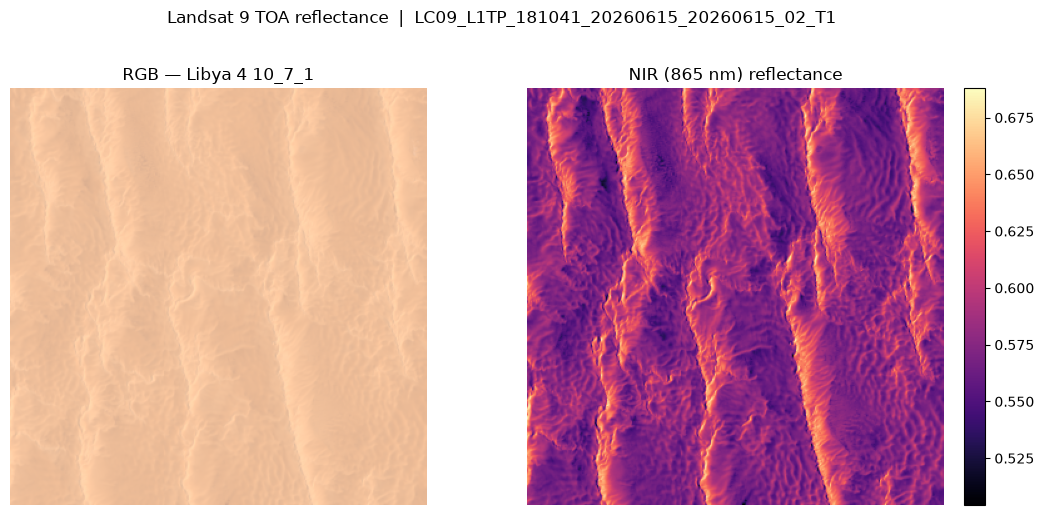

In [8]:
def rgb_composite(r, g, b, hi=None, gamma=1.4):
    """True-ish color. Use ONE shared scale across R/G/B so the warm desert band
    ratios (red > green > blue) survive — independent per-band stretching flattens
    them to gray. `hi=None` uses the per-scene 98th percentile; pass a fixed value
    (e.g. hi=0.5) for a consistent look across scenes in the eventual time series."""
    stack = np.ma.dstack([r, g, b]).astype("float64")
    if hi is None:
        hi = np.nanpercentile(stack.compressed(), 98)
    out = np.clip(stack / hi, 0, 1) ** (1 / gamma)
    return out.filled(0)   # masked fill -> black

fig, ax = plt.subplots(1, 2, figsize=(11, 5))

if all(k in arrays for k in ("red", "green", "blue")):
    rgb = rgb_composite(arrays["red"], arrays["green"], arrays["blue"])
    ax[0].imshow(rgb)
    ax[0].set_title(f"RGB — {SITE} {PATCH}")
else:
    ax[0].set_title("RGB unavailable")
ax[0].axis("off")

if "nir08" in arrays:
    im = ax[1].imshow(arrays["nir08"], cmap="magma")
    ax[1].set_title("NIR (865 nm) reflectance")
    fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)
ax[1].axis("off")

fig.suptitle(f"Landsat 9 {SRC['product']}  |  {item.id}", y=1.02)
plt.tight_layout()
plt.show()

## Notes & next steps

This proves the single-scene, single-patch extraction. To grow it into the control analysis:

1. **AWS creds for TOA.** Flip `SOURCE="usgs_toa"` and provide AWS credentials (boto3 default chain). Reads are
   requester-pays (small egress cost) from `usgs-landsat` in us-west-2.
2. **Loop the archive.** Iterate the STAC items (drop the `l9[0]` pick) to build a per-scene time series of the
   in-patch median per band, plus `datetime` and `cos(SZA)` — the design table for the quasi-BRDF fit.
3. **QC.** Add cloud/dust/edge screening (Landsat `qa_pixel` bitmask) to mirror the EMIT manual review.
4. **Band comparison.** Convolve EMIT channels with the OLI-2 relative spectral response before comparing, so
   the broad `nir08`/`swir22` bandpasses are matched fairly to EMIT's narrow channels.
5. **Fit.** Reuse `emit_pics.brdf_drift` on the Landsat design table — same `(α + β·cosθ)(1 + γt)` model — and
   compare γ against the EMIT result at the shared wavelengths.